<a href="https://colab.research.google.com/github/marensofiesteen/IND310/blob/main/Health_symptoms_patients_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

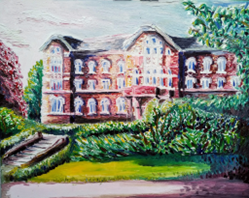

Jesper Ørntoft Frausig, 2023

\# Industrial understanding of healthcare sector

> Blokk med innrykk



# Install and prepare libraries

The "names" package in Python is install to generate syntetic names for patients

In [2]:
pip install names

Furrther the Python libraries such as pandas, numpy, names, random, and datetime are imported

In [4]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random  # Import the random module
import names   # Assuming you have the 'names' module installed


We donwload a medical archive CSV file from a URL, with specific delimiter, and displays the first few rows of the resulting DataFrame containing medical diagnosis and symptom data.

In [5]:
Medical_archieve=pd.read_csv("https://pvexpect.com/Healthcare/Medical_archieve.csv", delimiter=";")
Medical_archieve.head(10)

,Diagnosis,Symptom,Examination,Examination_2,Behandlding,Avdeling,Common/uncommon,"Sannsynlighet for kritisk utfall, når symptom er påvist",Kritiskhet kategori,Interview reveal,...,Diagnoses,Diagnoses_temp,Required Room(s),Departement(s),Required Equipment(s),Legehåndbok,Virtuell sykehus,Kostnader($),Sykdoms beskrivelse (Engelsk),Sykdoms beskrivelse (Norsk)
0,Acute Rheumatic Fever,Rheumatic Fever,an echocardiogram,NaN,antibiotics,Cardiology,Uncommon,100 %,Medium Hazard,False,...,"Bacterial tonsillitis, Laryngitis, Bronchitis,...",0,"Any office, Diagnostic unit",Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
1,Acute Rheumatic Fever,Sore Throat,an interview,an oral cavity inspection,analgesics,Cardiology,Uncommon,70 %,Low Hazard,True,...,All diseases involving pain.,0,"Any office, Diagnostic unit",Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
2,Acute Rheumatic Fever,Muscle and Joint Pain,an interview,a physical examination,rest,Cardiology,Uncommon,70 %,Medium Hazard,True,...,0,0,Office or Diagnostic unit,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
3,Acute Rheumatic Fever,Rash,an interview,a physical examination,steroid cream,Cardiology,Uncommon,70 %,Low Hazard,True,...,"Athlete's foot, Dermatomyositis",0,Office or Diagnostic unit,Emergency and Orthopeady,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
4,Acute Rheumatic Fever,Fever,an interview,temperature measurement,antipyretics,Cardiology,Uncommon,70 %,Medium Hazard,True,...,Diseases involving fever.,0,Office or Diagnostic unit,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
5,Acute Rheumatic Fever,Sweating,an interview,a physical examination,anticholinergics,Cardiology,Uncommon,70 %,Low Hazard,True,...,"Cluster headache, Tetanus, Bronchopneumonia, P...",0,Doctor's office or Observation room or ICU or ...,Internal Medicine or Cardiology or Neurology,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
6,Acute Rheumatic Fever,Chest Pain,an interview,thorax percussion,analgesics,Cardiology,Uncommon,70 %,Medium Hazard,True,...,All diseases involving pain.,0,"Any office, Diagnostic unit",Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
7,Acute Rheumatic Fever,Elevated CRP,a CRP test,NaN,NSAIDs,Cardiology,Uncommon,70 %,Low Hazard,False,...,Numerous conditions,0,Office or Diagnostic unit,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
8,Acute Rheumatic Fever,Swallow Pain,an interview,neck palpation,NSAIDs,Cardiology,Uncommon,60 %,Medium Hazard,True,...,Numerous conditions,0,Office or Diagnostic unit,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...
9,Acute Rheumatic Fever,Breathing Problems,an interview,chest auscultation,bronchodilators,Cardiology,Uncommon,60 %,Medium Hazard,True,...,"Hemolytic anemia, Cystic fibrosis, Bronchiecta...",0,Office or Diagnostic unit or ICU,Any,0.0,https://nhi.no/sykdommer/hjertekar/ulike-sykdo...,0,1100.0,Acute rheumatic fever is an inflammatory disea...,Akutt revmatisk feber er en inflammatorisk syk...


In [6]:
# Assuming you have already loaded the dataset into Medical_archieve
column_names = Medical_archieve.columns

# Print the column names
print(column_names)

Index(['Diagnosis', 'Symptom', 'Examination', 'Examination_2', 'Behandlding',
       'Avdeling', 'Common/uncommon',
       'Sannsynlighet for kritisk utfall, når symptom er påvist',
       'Kritiskhet kategori', 'Interview reveal', 'Symptom.1', 'ICON',
       'IsMainSymptom', 'DiscomfortLevel', 'PatientComplains', 'Hazard',
       'PatientMobility', 'Examination 1', 'Examination 2', 'Examination 3',
       'Treatment', 'ShameLevel', 'WalkAnim', 'WalkSpeedModifier',
       'CollapseSymptom', 'RiskOfCollapseStartHours', 'RiskOfCollapseEndHours',
       'CannotTalk', 'RiskOfDeathStartHours', 'RiskOfDeathEndHours',
       'CollapseProcedure', 'PlanAllTreatments', 'BleedingLevel',
       'Behandling (Engelsk)', 'Behandling (Norsk)',
       'Behandling beskrivelse (Engelsk)', 'Behandling beskrivelse (Norsk)',
       'Krav', 'Surgery room', 'Diagnoses', 'Diagnoses_temp',
       'Required Room(s)', 'Departement(s)', 'Required Equipment(s)',
       'Legehåndbok', 'Virtuell sykehus', 'Kostnader(

In [7]:
# Assuming you have already loaded the dataset into Medical_archieve
num_columns = Medical_archieve.shape[1]

# Print the number of columns
print("Number of columns:", num_columns)

Number of columns: 49


In [9]:
# Time slots
DAYS_OF_WEEK = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
TIME_SLOTS = [f"{day} {time}" for day in DAYS_OF_WEEK for time in ["9:00 AM - 12:00 PM", "12:00 PM - 3:00 PM", "3:00 PM - 6:00 PM"]]


def generate_arrival_time(slot, week_of_year):
    # Extract the day and time range from the slot
    day_name, time_range = slot.split(' ', 1)

    # Split the time range into start and end times
    start_time_str, end_time_str = time_range.split(' - ')

    # Map day names to numbers (Monday is 0, Sunday is 6)
    day_name_to_num = {'Monday': 0, 'Tuesday': 1, 'Wednesday': 2,
                       'Thursday': 3, 'Friday': 4, 'Saturday': 5, 'Sunday': 6}

    # Calculate the date for the desired week and weekday
    year = datetime.now().year
    reference_date = datetime(year, 1, 4)
    desired_date = reference_date + timedelta(weeks=week_of_year-1, days=day_name_to_num[day_name]-reference_date.weekday())

    # Convert the date part to a string in the appropriate format
    desired_date_str = desired_date.strftime("%Y-%m-%d")

    # Convert times to datetime objects and combine with the date part
    start_datetime = datetime.strptime(f"{desired_date_str} {start_time_str}", "%Y-%m-%d %I:%M %p")
    end_datetime = datetime.strptime(f"{desired_date_str} {end_time_str}", "%Y-%m-%d %I:%M %p")

    # Calculate the difference in seconds and add a random number of seconds to get the random time
    time_diff = int((end_datetime - start_datetime).total_seconds())
    random_seconds = random.randint(0, time_diff)
    random_time = start_datetime + timedelta(seconds=random_seconds)

    return random_time



Then we develop a function, `generate_patient()`, that creates a random patient profile by selecting a disease, generating various patient attributes such as name, planned appointment, hazard level, timeslot, arrival time, revealed and unrevealed symptoms, and diagnosis based on a medical archive dataset.

In [12]:
def generate_patient():
    # Choose a random disease from the archive. a single random sample row is
    #selected from the Medical_archieve DataFrame. This selected row is then
    #assigned to the variable disease_info. The .sample(1) function is used to
    #randomly select one row, and .iloc[0] is used to extract that row into the
    #disease_info variable.
    disease_info = Medical_archieve.sample(1).iloc[0]
    #print('disease infor is', disease_info)
    # Generating a random weekday and timeslot for the patient
    #patient = {}: An empty dictionary named patient is initialized.
    #This dictionary will store information about a patient.
    patient = {}
    #This code attempts to set the 'Name' key in the patient dictionary to a randomly generated full name.
    #The function get_full_name() from the names module is used for this purpose.
    patient['Name'] = names.get_full_name()
    #patient['Planned'] = random.choice([True, False]): This line assigns a random choice of either True
    #or False to the 'Planned' key in the patient dictionary. It uses the random.choice() function to
    #randomly select one of the values from the list [True, False]. This could represent whether a
    #medical procedure or treatment for the patient is planned or not.
    patient['Planned'] = random.choice([True, False])
    #patient['Hazard'] = disease_info['Hazard']: The 'Hazard' key in the patient dictionary is
    #assigned the value of 'Kritiskhet kategori' from the disease_info DataFrame.
    patient['Kritiskhet kategori'] = disease_info['Kritiskhet kategori']
    #patient['Weekday'] = random.choice(weekdays)
    #patient['Timeslot'] = random.choice(TIME_SLOTS)
    # New: Generate a specific arrival time within the timeslot
    #patient['Week_of_Year'] = random.randint(1, 52)
    #patient['Arrival_Time'] = generate_arrival_time(patient['Timeslot'], patient['Week_of_Year'])
    patient['IsMainSymptom'] = disease_info['IsMainSymptom']
    patient['DiscomfortLevel'] = disease_info['DiscomfortLevel']
    patient['PatientComplains'] = disease_info['PatientComplains']
    patient['PatientMobility'] = disease_info['PatientMobility']
    patient['CannotTalk'] = disease_info['CannotTalk']
    patient['BleedingLevel'] = disease_info['BleedingLevel']

    # the code creates a new DataFrame revealed_symptoms_df that contains only the 'Symptom' column
    #data from rows in the Medical_archieve DataFrame where the 'Diagnosis' matches the diagnosis
    #in disease_info and 'Interview reveal' is True.
    revealed_symptoms_df = Medical_archieve[
        (Medical_archieve.Diagnosis == disease_info['Diagnosis']) &
        (Medical_archieve['Interview reveal'] == True)
    ].Symptom
    #print(revealed_symptoms_df)
    #131            Chest Pain
    #132            Hemoptysis
    #133    Breathing Problems
    #135                 Edema
    #136               Fatigue
    #137             Dizziness
    #138              Fainting
    #Name: Symptom, dtype: object
    #The code is determining the value of the variable n_sample.
    #If the length of revealed_symptoms_df is less than 3, it sets n_sample to that length.
    #If the length of revealed_symptoms_df is 3 or more, it sets n_sample to 3.
    n_sample = min(len(revealed_symptoms_df), 3)
    #patient['Revealed_Symptoms'] = list(revealed_symptoms_df.sample(n_sample)):

    #revealed_symptoms_df.sample(n_sample) takes a random sample of symptoms from
    #the revealed_symptoms_df DataFrame. The n_sample variable specifies the number
    #of symptoms to be sampled. This creates a list of symptoms.
    patient['Revealed_Symptoms'] = list(revealed_symptoms_df.sample(n_sample))
    #print(list(revealed_symptoms_df.sample(n_sample)))
    #['Itching', 'Rash On Leg', 'Rash On Arm']
    #filters the 'Medical_archieve' DataFrame to select rows where the diagnosis matches
    #the diagnosis in 'disease_info' and 'Interview reveal' is False. It then extracts
    #the 'Symptom' column from these filtered rows.
    patient['Unrevealed_Symptoms'] = list(Medical_archieve[(Medical_archieve.Diagnosis==disease_info['Diagnosis'])&(Medical_archieve['Interview reveal']==False)].Symptom)
    patient['Diagnosis'] = disease_info['Diagnosis']
    return patient


patient = generate_patient()
print(patient)

{'Name': 'Christina Mccall', 'Planned': True, 'Kritiskhet kategori': ' Medium Hazard', 'IsMainSymptom': 'FALSE', 'DiscomfortLevel': 'Medium', 'PatientComplains': 'TRUE', 'PatientMobility': 'MOBILE', 'CannotTalk': '0', 'BleedingLevel': '0', 'Revealed_Symptoms': ['Redness', 'Swelling', 'Pain In the Ears'], 'Unrevealed_Symptoms': ['Fracture of the Mandible'], 'Diagnosis': 'Mandibular Fracture'}


In [19]:
# Velg antall pasienter
antall_pasienter = 3

# Generer pasientene
pasienter = [generate_patient() for _ in range(antall_pasienter)]

# Samle dem i en tabell
pasienter_df = pd.DataFrame(pasienter)

# Vis de første 10 pasientene
pasienter_df.head(10)

,Name,Planned,Kritiskhet kategori,IsMainSymptom,DiscomfortLevel,PatientComplains,PatientMobility,CannotTalk,BleedingLevel,Revealed_Symptoms,Unrevealed_Symptoms,Diagnosis
0,Dewey Johnson,False,Medium Hazard,NaN,NaN,NaN,NaN,NaN,NaN,"[Breathing Problems, Hemoptysis, High Fever]","[B. Anthracis Detected, Sore Throat, Fatigue, ...",Pulmonary Anthrax
1,Brittney Vineyard,True,High Hazard,NaN,NaN,NaN,NaN,NaN,NaN,"[Dizziness, Breathing Problems, Fever]","[Nipah Virus Detected, Unconsciousness]",Nipah Virus Infection
2,Nancy Ponce,False,Low Hazard,FALSE,Low,TRUE,MOBILE,0,0,"[Weakness, Fatigue, Urinary Incontinence]","[Demyelinization Findings, Autoimmune Antibodies]",CIPD


The function `get_possible_diagnoses_probability` analyzes a patient's revealed symptoms against a medical archive to compute and return the probability of possible diagnoses.

In [20]:
def get_possible_diagnoses_probability(patient):
    # Load Data
    Medical_archieve = pd.read_csv("https://pvexpect.com/Healthcare/Medical_archieve.csv", delimiter=";")
    revealed_symptoms = patient['Revealed_Symptoms']
    #print(revealed_symptoms)

    #This line of code is adding a new column, 'Symptom Identified,' to
    #the 'Medical_archieve' DataFrame. the code checks if each value in the 'Symptom' column
    #of the 'Medical_archieve' DataFrame is present in the 'revealed_symptoms' list.
    #This operation results in a Boolean Series where each element is True if the symptom is in
    #the 'revealed_symptoms' list and False if it's not. After creating the Boolean Series, .astype(int)
    #is used to convert the Boolean values (True and False) to integers (1 for True and 0 for False).

    Medical_archieve['Symptom Identified'] = Medical_archieve['Symptom'].isin(revealed_symptoms).astype(int)
    #Medical_archieve.head(5)
    #It calculates the sum of values in the 'Symptom Identified' column for each group
    #(each unique 'Diagnosis'). The result is the total count of True values in the
    #'Symptom Identified' column for each diagnosis.
    #This operation is appropriate when 'Symptom Identified' is a binary indicator
    #(e.g., 1 for True and 0 for False), and you want to count the occurrences of True within
    #each group (diagnosis).
    symptom_counts = Medical_archieve.groupby('Diagnosis')['Symptom Identified'].sum().reset_index()
    #grouped_by_diagnosis = Medical_archieve.groupby('Diagnosis')
    #print("Step 1: Grouped by Diagnosis")
    #print(grouped_by_diagnosis.head())  # Display the first few rows of each group
    #symptom_count_per_diagnosis = grouped_by_diagnosis['Symptom Identified'].sum()
    #print("\nStep 2: Sum of 'Symptom Identified' within each group")
    #print(symptom_count_per_diagnosis.head(200))  # Display the summed symptom count for each group
    #symptom_counts = symptom_count_per_diagnosis.reset_index()
    #print("\nStep 3: Reset the index")
    #Num_columns = symptom_counts.shape[1]
    #print("Number of columns:", Num_columns)
    #print(symptom_counts.head(20))  # Display the final DataFrame with diagnosis and symptom count
    #Diagnosis  Symptom Identified
    #0                  ACL Injury                   0
    #1                        ASOM                   0
    #2   Abdominal Ballistic Wound                   1
    #3      Abdominal Blast Trauma                   1
    #4   Abdominal Shattered Wound                   1
    #5        Abdominal Stab Wound                   1
    #6           Acute Hepatitis E                   2

    #It calculates the total count of non-null (non-missing) values in the 'Symptom' column for each
    #group (each unique 'Diagnosis'). The result is the total number of symptoms
    #(regardless of whether they were identified or not) for each diagnosis.
    #This operation is appropriate when you want to count all occurrences of symptoms within
    #each group (diagnosis) without considering their identification status.
    total_symptoms_per_diagnosis = Medical_archieve.groupby('Diagnosis')['Symptom'].count().reset_index()
    #print(total_symptoms_per_diagnosis.head(20))
    #                    Diagnosis  Symptom
    #0                  ACL Injury        6
    #1                        ASOM        9
    #2   Abdominal Ballistic Wound       16
    #3      Abdominal Blast Trauma       22
    #4   Abdominal Shattered Wound       21
    #5        Abdominal Stab Wound       19
    #6           Acute Hepatitis E       10
    #7           Acute Mastoiditis       10
    #8         Acute Osteomyelitis        8

    #This line of code is used to rename the columns of the DataFrame total_symptoms_per_diagnosis. It assigns new column names to the DataFrame's columns as follows:
    #The original column name 'Diagnosis' is renamed to 'Diagnosis'. In this case,
    #it remains the same, so no change occurs. The original column name 'Total Symptoms'
    #is renamed to 'Total Symptoms'. Again, it remains the same.
    #In summary, this line of code doesn't change the column names in the DataFrame.
    #It explicitly assigns the same names to the columns to ensure they match the specified names,
    #but in this case, they already match, so there's no actual change. This operation is often
    #used when you want to make sure your DataFrame columns have specific, predefined names for
    #clarity or consistency.
    total_symptoms_per_diagnosis.columns = ['Diagnosis', 'Total Symptoms']

    #Merge to get probabilities. performs a merge operation between two DataFrames, symptom_counts
    #and total_symptoms_per_diagnosis, based on the common column 'Diagnosis'. The resulting symptom_counts
    #DataFrame will contain the information from both symptom_counts and total_symptoms_per_diagnosis.
    #The common column 'Diagnosis' will act as the key for combining the data, resulting in a single
    #DataFrame that combines the symptom counts with the total symptom counts for each diagnosis.
    symptom_counts = pd.merge(symptom_counts, total_symptoms_per_diagnosis, on='Diagnosis')
    #print(symptom_counts.head(50))
    #                      Diagnosis  Symptom Identified  Total Symptoms
    #0                    ACL Injury                   0               6
    #1                          ASOM                   1               9
    #2     Abdominal Ballistic Wound                   0              16
    #3        Abdominal Blast Trauma                   0              22
    #4     Abdominal Shattered Wound                   0              21
    #5          Abdominal Stab Wound                   0              19
    #6             Acute Hepatitis E                   2              10
    #7             Acute Mastoiditis                   1              10
    #8           Acute Osteomyelitis                   1               8
    #9           Acute Renal Failure                   0              15
    #10        Acute Rheumatic Fever                   2              14
    #11      African Tick Bite Fever                   2              10
    #12       American Trypanosomias                   4              24

    #symptom_counts['Probability']: This part of the code assigns the result of the division to a
    #new column 'Probability' in the symptom_counts DataFrame. Each row in this column will
    #represent the probability of identifying a symptom for the corresponding diagnosis.
    symptom_counts['Probability'] = symptom_counts['Symptom Identified'] / symptom_counts['Total Symptoms']
    #print(symptom_counts.head(5))
    #                   Diagnosis  Symptom Identified  Total Symptoms  Probability
    #0                 ACL Injury                   0               6     0.000000
    #1                       ASOM                   1               9     0.111111
    #2  Abdominal Ballistic Wound                   0              16     0.000000
    #3     Abdominal Blast Trauma                   0              22     0.000000
    #4  Abdominal Shattered Wound                   0              21     0.000000

    # Filter diagnoses that meet the condition (have all the patient's symptoms).
    #valid_diagnoses: This is a new DataFrame that stores the result of the filtering operation.
    #It will contain only the rows (diagnoses) from the symptom_counts DataFrame where the
    #condition specified is met. In other words, it retains diagnoses for which the count of
    #identified symptoms is greater than or equal to the length of revealed_symptoms.
    #So, the resulting valid_diagnoses DataFrame contains the diagnoses where a sufficient
    #number of symptoms have been identified, based on the comparison with the length of revealed_symptoms.
    #These are considered "valid" diagnoses.
    valid_diagnoses = symptom_counts[symptom_counts["Symptom Identified"] >= len(revealed_symptoms)]
    # print(valid_diagnoses.head(5))
    #                  Diagnosis  Symptom Identified  Total Symptoms  Probability
    #12   American Trypanosomias                   4              24     0.166667
    #21             Appendicitis                   4              21     0.190476
    #31               Babesiosis                   4              18     0.222222
    #103         Crohn's Disease                   3              15     0.200000
    #133              Gallstones                   3              10     0.300000

    #[['Diagnosis', 'Probability']]: This part of the code selects only two columns
    #from the valid_diagnoses DataFrame, namely "Diagnosis" and "Probability." It creates
    #a new DataFrame that includes only these two columns. reset_index(drop=True): This
    #part of the code resets the index of the DataFrame. When a DataFrame is filtered,
    #it may retain the original index values from the source DataFrame.
    #By using reset_index(drop=True), you are resetting the index to a default integer-based
    #index and dropping the previous index, which might not be continuous if there were
    #rows removed during filtering. This results in a cleaner, continuous index for the
    #new DataFrame. So, result_df is a new DataFrame that contains only the "Diagnosis"
    #and "Probability" columns from the valid_diagnoses DataFrame, and it has a reset index.
    #This DataFrame is more compact and suitable for further processing or presentation of
    #the results.
    result_df = valid_diagnoses[['Diagnosis', 'Probability']].reset_index(drop=True)

    return result_df
from IPython.display import display, Markdown

patient = generate_patient()
possible_diagnoses_df = get_possible_diagnoses_probability(patient)

# Norske navn for visningen
feltnavn = {
    'Name': 'Navn',
    'Planned': 'Planlagt besøk',
    'Kritiskhet kategori': 'Kritiskhetskategori',
    'IsMainSymptom': 'Hovedsymptom',
    'DiscomfortLevel': 'Ubehagsnivå',
    'PatientComplains': 'Pasienten oppgir plager',
    'PatientMobility': 'Mobilitet',
    'CannotTalk': 'Kan ikke snakke',
    'BleedingLevel': 'Blødningsnivå',
    'Revealed_Symptoms': 'Oppgitte symptomer',
    'Unrevealed_Symptoms': 'Skjulte symptomer',
    'Diagnosis': 'Generert diagnose'
}

# Gjør verdiene lettere å lese
def formater_verdi(felt, verdi):
    if isinstance(verdi, list):
        return ', '.join(verdi) if verdi else 'Ingen'

    if pd.isna(verdi):
        return 'Mangler opplysning'

    if felt in ['Planned', 'IsMainSymptom',
                'PatientComplains', 'CannotTalk']:
        return {
            'True': 'Ja', 'TRUE': 'Ja',
            'False': 'Nei', 'FALSE': 'Nei', '0': 'Nei'
        }.get(str(verdi), str(verdi))

    oversettelser = {
        'Low Hazard': 'Lav',
        'Medium Hazard': 'Middels',
        'High Hazard': 'Høy',
        'Low': 'Lav',
        'Medium': 'Middels',
        'High': 'Høy',
        'MOBILE': 'Mobil',
        'IMMOBILE': 'Immobil',
        'INTUBATED': 'Intubert'
    }

    tekst = str(verdi).strip()
    return oversettelser.get(tekst, tekst)

pasienttabell = pd.DataFrame([
    {
        'Opplysning': feltnavn.get(felt, felt),
        'Verdi': formater_verdi(felt, verdi)
    }
    for felt, verdi in patient.items()
])

display(Markdown("### Generert pasient"))
display(pasienttabell.style.hide(axis='index'))

diagnosetabell = possible_diagnoses_df.rename(columns={
    'Diagnosis': 'Mulig diagnose',
    'Probability': 'Andel samsvarende symptomer'
})

display(Markdown("### Diagnoser som matcher symptomene"))
display(
    diagnosetabell.style
    .format({'Andel samsvarende symptomer': '{:.1%}'})
    .hide(axis='index')
)



### Generert pasient

Opplysning,Verdi
Navn,Juan Frawley
Planlagt besøk,Nei
Kritiskhetskategori,Middels
Hovedsymptom,Nei
Ubehagsnivå,Middels
Pasienten oppgir plager,Ja
Mobilitet,Mobil
Kan ikke snakke,Nei
Blødningsnivå,0
Oppgitte symptomer,"Fever, Loss of Appetite, Night Sweats"


### Diagnoser som matcher symptomene

Mulig diagnose,Andel samsvarende symptomer
American Trypanosomias,16.7%
Appendicitis,14.3%
Brucellosis,20.0%
Mumps,19.0%
Pulmonary NTMB Infection,18.8%
Tuberculosis,18.8%
